# Model Improvement, Bias–Variance Diagnosis and Literature Comparison

**Project:** Explainable Inhibitor Risk Classification for Haemophilia A Using Fused Genomic–Clinical Data
**Project ID:** PW26_DN_03 · PES University · Notebook 02 (follows `01_dataset_cleaning_and_feature_selection.ipynb`)

This notebook responds point by point to the reviewer's comments on the project report (Nov 2026):

| # | Reviewer comment | Where it is answered |
|---|---|---|
| 1 | *"On train CV the ROC-AUC is less than 50% but on testing ROC-AUC is around 70%+"* | **Section 3** – the 0.453 figure in the report was the *majority-class baseline row*, not a model. It is an artefact of pooling a constant predictor across folds; every trained model scored 0.73–0.76 in CV. Fixed and re-reported per fold. |
| 2 | *"ROC-AUC is not a good metric to deal with"* | **Section 4** – the headline is now a full imbalance-aware panel: PR-AUC, MCC, balanced accuracy, F1, sensitivity, specificity, precision, Brier score, and accuracy next to the majority-class accuracy. |
| 3 | *"The model has high bias, low variance"* | **Section 5** – learning curves, a capacity sweep and a label-noise analysis show *where* the error comes from and what more capacity can and cannot fix. |
| 4 | *Improve the results* | **Section 6** – new biology features, a four-model ensemble, thresholds chosen inside training folds only, 5×5 repeated variant-grouped CV; before/after table. **Section 7** – the "known-variant" use case. |
| 5 | *"Papers report >90% — make a comparison table explaining your results vs. theirs"* | **Section 8** – the literature protocol is **re-run on our own data**: it reproduces >90% accuracy, and each step that produces it is removed one at a time. Final comparison table with every base paper. |

**Self-contained.** The notebook needs only the two raw supplementary files (`mmc2.csv`, `mmc3.csv`). It re-implements the
cleaning of notebook 01 (same rules, same counts) so it can run on any machine. Run time ≈ 25–35 min on 8 cores.

## 1. Setup

In [1]:
import math, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, f1_score, matthews_corrcoef, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
N_JOBS = 8
T0 = time.time()

# Locate the raw files: the project layout (data/raw/mmc2.csv) or the supplement's original file names.
def find_raw(kind):
    names = [f"{kind}.csv", f"BVTH_VTH-2024-000215-{kind}.csv"]
    roots = [Path.cwd(), *Path.cwd().parents, Path.home() / "Downloads"]
    for root in roots:
        for sub in ["data/raw", "data/raw/hadb", "."]:
            for n in names:
                p = root / sub / n
                if p.exists():
                    return p
    raise FileNotFoundError(f"{kind}.csv not found - put it in data/raw/ next to this notebook")

MMC2, MMC3 = find_raw("mmc2"), find_raw("mmc3")
print("MMC2:", MMC2, "\nMMC3:", MMC3)

MMC2: C:\Users\Dipak\Downloads\BVTH_VTH-2024-000215-mmc2.csv 
MMC3: C:\Users\Dipak\Downloads\BVTH_VTH-2024-000215-mmc3.csv


## 2. Data preparation (same rules as notebook 01)

The helper code below reproduces notebook 01's cleaning: unknown outcomes are **kept out, never set to "no inhibitor"**;
shifted rows, gnomAD population rows, unmatched and F9 variants are removed; `mut_id`s that share an HGVS cDNA or
protein name are merged into one `variant_key` (union-find), the unit that is never split between training and test.

It also holds the biology reference tables used by the new features (FVIII domain map, inhibitor epitopes, amino-acid
physicochemistry, Grantham distance, BLOSUM62). These are prior knowledge from UniProt P00451 and the epitope
literature — none of them is derived from the outcome labels.

In [2]:
# ---------------------------------------------------------------- cleaning
MISSING = {"", "-", "?", "na", "nan", "none", "not", "not r", "not report", "not reported", "null", "n/a"}

def clean_str(v):
    if v is None or (isinstance(v, float) and math.isnan(v)):
        return ""
    s = str(v).strip()
    return "" if s.lower() in MISSING else s

def variant_key(m2):
    """Union-find: mut_ids sharing an HGVS cDNA or protein name are one biological variant."""
    parent = {m: m for m in m2["mut_id"]}
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for col in ("mut_syn", "aa_syn"):
        first = {}
        for mid, name in zip(m2["mut_id"], m2[col].map(lambda s: clean_str(s).lower())):
            if not name:
                continue
            if name in first:
                a, b = find(mid), find(first[name])
                if a != b:
                    parent[a] = b
            else:
                first[name] = mid
    return {m: "v" + find(m) for m in parent}

VARIANT_COLS = ["mut_id", "mut_type", "mut_effect", "d_id", "location", "e_i_numb", "locnumb", "aa_numb", "n_bp",
                "nuc_numb", "ntchange", "codon_first", "codon_last", "aa_first", "aa_last", "mut_syn", "aa_syn"]

def load_reports(keep_unknown=False):
    m2 = pd.read_csv(MMC2, dtype=str, keep_default_na=False)
    m3 = pd.read_csv(MMC3, dtype=str, keep_default_na=False)
    flow = [("raw MMC3 reports", len(m3), np.nan)]
    lab = m3["Inhibitors"].str.strip().str.lower()
    m3["y"] = lab.map({"yes": 1.0, "no": 0.0})
    def step(name, mask):
        nonlocal m3
        m3 = m3[mask]; flow.append((name, len(m3), int(m3["y"].sum())))
    step("shifted-column rows removed", ~lab.loc[m3.index].isin({"mild", "severe", "moderate"}))
    step("gnomAD population rows removed", m3["reference"].str.strip().str.lower() != "gnomad v2.1.1")
    step("mut_id missing from MMC2 removed", m3["mut_id"].isin(set(m2["mut_id"])))
    f8 = m2[m2["g_name"].str.strip().str.upper() == "F8"]
    step("F9 (haemophilia B) variants removed", m3["mut_id"].isin(set(f8["mut_id"])))
    if not keep_unknown:
        step("unknown outcome removed (never set to 0)", m3["y"].notna())
    df = m3.merge(m2[VARIANT_COLS], on="mut_id", how="left", validate="many_to_one").reset_index(drop=True)
    df["variant_key"] = df["mut_id"].map(variant_key(f8))
    return df, pd.DataFrame(flow, columns=["step", "rows remaining", "positives"])

# ---------------------------------------------------------------- parsing
def parse_level(v):
    """FVIII level -> (value, how reported). '<1' -> 0.5 (half the bound); '23 to 40' -> midpoint."""
    s = clean_str(v).replace("%", "").replace(",", ".")
    if not s:
        return np.nan, "missing"
    s = s.split("|")[0].strip()
    m = re.fullmatch(r"([<>])=?\s*([\d.]+)\??", s)
    if m:
        val = float(m.group(2))
        return (val * 0.5, "upper_bound") if m.group(1) == "<" else (val, "lower_bound")
    m = re.fullmatch(r"([\d.]+)\s*(?:to|-|–|and)\s*([\d.]+)\??", s, flags=re.I)
    if m:
        return (float(m.group(1)) + float(m.group(2))) / 2.0, "range_mid"
    m = re.match(r"^([\d.]+)", s)
    if m:
        try:
            return float(m.group(1)), "exact"
        except ValueError:
            pass
    return np.nan, "missing"

def severity(v):
    s = clean_str(v).lower().replace(" ", "")
    if not s or s in {"unclassified", "notreported", "notaffected"}:
        return "unknown"
    if "mild" in s and "mod" in s:
        return "mild_moderate"
    if s in {"non-severe", "nonsevere"}:
        return "moderate"
    if re.search(r"sev|svere", s):
        return "severe"
    if re.search(r"mod|moderare|mpderate", s):
        return "moderate"
    return "mild" if "mild" in s else "unknown"

def effect(v):
    s = clean_str(v).lower()
    if not s:
        return "unknown"
    if "large" in s and "del" in s:
        return "large_deletion"
    if "large" in s and ("dup" in s or "ins" in s):
        return "large_duplication"
    for k, lab in (("nonsense", "nonsense"), ("frameshift", "frameshift"), ("missense", "missense"), ("splic", "splice")):
        if k in s:
            return lab
    if "silent" in s or "synonym" in s:
        return "silent"
    return "in_frame" if ("in-frame" in s or "inframe" in s) else "other"

DOMAIN_MAP = {"5utr": "utr", "3utr": "utr", "5-utr": "utr", "3-utr": "utr", "a1-a2": "multiple", "a1-a1-a2": "multiple",
              "a3-c1": "multiple", "c1-c2": "multiple", "multiple domains": "multiple", "undefined": "unknown"}
domain = lambda v: DOMAIN_MAP.get(clean_str(v).lower(), clean_str(v).lower() or "unknown")

def exon_number(v):
    s = clean_str(v)
    if not re.fullmatch(r"\d+", s):
        return np.nan
    n = int(s)
    return float(n) if 1 <= n <= 26 else np.nan      # values > 26 are spreadsheet date serials

AA3 = {"ala": "A", "arg": "R", "asn": "N", "asp": "D", "cys": "C", "gln": "Q", "glu": "E", "gly": "G", "his": "H",
       "ile": "I", "leu": "L", "lys": "K", "met": "M", "phe": "F", "pro": "P", "ser": "S", "thr": "T", "trp": "W",
       "tyr": "Y", "val": "V", "ter": "*", "*": "*", "stop": "*"}
def aa1(v):
    s = clean_str(v).lower()
    if not s:
        return ""
    if s in AA3:
        return AA3[s]
    if len(s) == 1 and s.upper() in "ARNDCQEGHILKMFPSTWYV*":
        return s.upper()
    return "fs" if "fs" in s else "other"

In [3]:
# ---------------------------------------------------------------- biology reference tables (UniProt P00451, literature)
SIG, MATURE, HEAVY_LIGHT = 19, 2332, 1648
INHIBITOR_EPITOPES = [(484, 508), (1804, 1819), (2091, 2115), (2181, 2243), (2248, 2312)]   # A2, A3, C1, C2 x2
FUNCTIONAL_SITES = [(1670, 1684), (1811, 1818), (337, 372), (2199, 2332), (372, 372), (740, 740), (1689, 1689)]
HYDROPATHY = dict(A=1.8, R=-4.5, N=-3.5, D=-3.5, C=2.5, Q=-3.5, E=-3.5, G=-0.4, H=-3.2, I=4.5, L=3.8, K=-3.9, M=1.9,
                  F=2.8, P=-1.6, S=-0.8, T=-0.7, W=-0.9, Y=-1.3, V=4.2)
VOLUME = dict(A=88.6, R=173.4, N=114.1, D=111.1, C=108.5, Q=143.8, E=138.4, G=60.1, H=153.2, I=166.7, L=166.7,
              K=168.6, M=162.9, F=189.9, P=112.7, S=89.0, T=116.1, W=227.8, Y=193.6, V=140.0)
POLARITY = dict(A=8.1, R=10.5, N=11.6, D=13.0, C=5.5, Q=10.5, E=12.3, G=9.0, H=10.4, I=5.2, L=4.9, K=11.3, M=5.7,
                F=5.2, P=8.0, S=9.2, T=8.6, W=5.4, Y=6.2, V=5.9)
CHARGE = {**{a: 0.0 for a in HYDROPATHY}, "D": -1.0, "E": -1.0, "K": 1.0, "R": 1.0}
COMPOSITION = dict(S=1.42, R=0.65, L=0.0, P=0.39, T=0.71, A=0.0, V=0.0, G=0.74, I=0.0, F=0.0, Y=0.20, C=2.75,
                   H=0.58, Q=0.89, N=1.33, K=0.33, D=1.38, E=0.92, M=0.0, W=0.13)
AROMATIC = set("FWY")

def grantham(a, b):
    """Grantham (1974) distance from its published composition/polarity/volume formula."""
    if a not in POLARITY or b not in POLARITY:
        return np.nan
    d = 1.833 * (COMPOSITION[a] - COMPOSITION[b]) ** 2 + 0.1018 * (POLARITY[a] - POLARITY[b]) ** 2 \
        + 0.000399 * (VOLUME[a] - VOLUME[b]) ** 2
    return 50.723 * d ** 0.5

_B62 = "ARNDCQEGHILKMFPSTWYV"
_B62_ROWS = """4 -1 -2 -2 0 -1 -1 0 -2 -1 -1 -1 -1 -2 -1 1 0 -3 -2 0|-1 5 0 -2 -3 1 0 -2 0 -3 -2 2 -1 -3 -2 -1 -1 -3 -2 -3|
-2 0 6 1 -3 0 0 0 1 -3 -3 0 -2 -3 -2 1 0 -4 -2 -3|-2 -2 1 6 -3 0 2 -1 -1 -3 -4 -1 -3 -3 -1 0 -1 -4 -3 -3|
0 -3 -3 -3 9 -3 -4 -3 -3 -1 -1 -3 -1 -2 -3 -1 -1 -2 -2 -1|-1 1 0 0 -3 5 2 -2 0 -3 -2 1 0 -3 -1 0 -1 -2 -1 -2|
-1 0 0 2 -4 2 5 -2 0 -3 -3 1 -2 -3 -1 0 -1 -3 -2 -2|0 -2 0 -1 -3 -2 -2 6 -2 -4 -4 -2 -3 -3 -2 0 -2 -2 -3 -3|
-2 0 1 -1 -3 0 0 -2 8 -3 -3 -1 -2 -1 -2 -1 -2 -2 2 -3|-1 -3 -3 -3 -1 -3 -3 -4 -3 4 2 -3 1 0 -3 -2 -1 -3 -1 3|
-1 -2 -3 -4 -1 -2 -3 -4 -3 2 4 -2 2 0 -3 -2 -1 -2 -1 1|-1 2 0 -1 -3 1 1 -2 -1 -3 -2 5 -1 -3 -1 0 -1 -3 -2 -2|
-1 -1 -2 -3 -1 0 -2 -3 -2 1 2 -1 5 0 -2 -1 -1 -1 -1 1|-2 -3 -3 -3 -2 -3 -3 -3 -1 0 0 -3 0 6 -4 -2 -2 1 3 -1|
-1 -2 -2 -1 -3 -1 -1 -2 -2 -3 -3 -1 -2 -4 7 -1 -1 -4 -3 -2|1 -1 1 0 -1 0 0 0 -1 -2 -2 0 -1 -2 -1 4 1 -3 -2 -2|
0 -1 0 -1 -1 -1 -1 -2 -2 -1 -1 -1 -1 -2 -1 1 5 -2 -2 0|-3 -3 -4 -4 -2 -2 -3 -2 -2 -3 -2 -3 -1 1 -4 -3 -2 11 2 -3|
-2 -2 -2 -3 -2 -1 -2 -3 2 -1 -1 -2 -1 3 -3 -2 -2 2 7 -1|0 -3 -3 -3 -1 -2 -2 -3 -3 3 1 -2 1 -1 -2 -2 0 -3 -1 4"""
BLOSUM62 = {(_B62[i], _B62[j]): int(v) for i, row in enumerate(_B62_ROWS.replace("\n", "").split("|"))
            for j, v in enumerate(row.split())}

def dist_to_span(p, lo, hi):
    return np.nan if p != p else (lo - p if p < lo else (p - hi if p > hi else 0.0))

In [4]:
# ---------------------------------------------------------------- feature sets
NULL_EFFECTS = {"large_deletion", "large_duplication", "nonsense", "frameshift"}

def base_columns(df):
    """Row-wise parsing; uses no labels and no other rows, so it cannot leak across folds."""
    b = pd.DataFrame(index=df.index)
    b["effect"] = df["mut_effect"].map(effect)
    b["mut_type"] = df["mut_type"].map(lambda v: clean_str(v).lower() or "unknown").replace({"duptication": "duplication"})
    b["domain"] = df["d_id"].map(domain)
    b["location"] = df["location"].map(lambda v: clean_str(v).lower().split(" ")[0].strip("/") or "unknown") \
                                  .replace({"promote": "promoter", "5utr": "utr"})
    b["severity"] = df["cli_phe"].map(severity)
    b["nt_change"] = df["ntchange"].map(lambda v: clean_str(v).upper().replace(" ", "") or "unknown")
    b["aa_ref"] = df["aa_first"].map(aa1).replace("", "none")
    b["aa_alt"] = df["aa_last"].map(aa1).replace("", "none")
    b["crm_type"] = df["type"].map(lambda v: clean_str(v).lower()).where(lambda s: s.isin(["i", "ii"]), "unknown")
    for col, src in (("fviii_activity", "clotting"), ("fviii_antigen", "antigen")):
        parsed = df[src].map(parse_level)
        b[col] = [v for v, _ in parsed]; b[col + "_kind"] = [k for _, k in parsed]
    b["aa_position"] = pd.to_numeric(df["aa_numb"], errors="coerce").replace(0, np.nan)
    b["cdna_position"] = pd.to_numeric(df["nuc_numb"], errors="coerce")
    b["exon"] = df["e_i_numb"].map(exon_number)
    b["n_bp"] = pd.to_numeric(df["n_bp"], errors="coerce")
    b["codon_ref"] = df["codon_first"].map(lambda v: clean_str(v).lower())
    return b

def features_v1(b):
    """The report's 'combined' set: 13 numeric + 11 categorical inputs (115 encoded columns in notebook 01)."""
    f = pd.DataFrame(index=b.index)
    f["cdna_position"], f["aa_position"], f["exon_intron_number"] = b["cdna_position"], b["aa_position"], b["exon"]
    f["log_n_bp"] = np.log10(b["n_bp"].clip(lower=1))
    sub = b["aa_ref"].isin(list(HYDROPATHY)) & b["aa_alt"].isin(list(HYDROPATHY))
    f["hydropathy_change"] = np.where(sub, b["aa_alt"].map(HYDROPATHY) - b["aa_ref"].map(HYDROPATHY), np.nan)
    f["charge_change"] = np.where(sub, b["aa_alt"].map(CHARGE) - b["aa_ref"].map(CHARGE), np.nan)
    f["cys_gained"] = np.where(sub, (b["aa_alt"] == "C").astype(float), np.nan)
    f["cys_lost"] = np.where(sub, (b["aa_ref"] == "C").astype(float), np.nan)
    f["arg_lost"] = np.where(b["aa_ref"] != "none", ((b["aa_ref"] == "R") & (b["aa_alt"] != "R")).astype(float), np.nan)
    f["ref_codon_has_cpg"] = np.where(b["codon_ref"] != "", b["codon_ref"].str.contains("cg").astype(float), np.nan)
    snv = b["nt_change"].str.fullmatch(r"[ACGT]>[ACGT]")
    f["is_transition"] = np.where(snv, b["nt_change"].isin(["A>G", "G>A", "C>T", "T>C"]).astype(float), np.nan)
    f["log_fviii_activity"] = np.log10(b["fviii_activity"] + 0.1)
    f["log_fviii_antigen"] = np.log10(b["fviii_antigen"] + 0.1)
    cat = b[["mut_type", "effect", "domain", "location", "nt_change", "aa_ref", "severity", "crm_type",
             "fviii_activity_kind", "fviii_antigen_kind"]].copy()
    cat["aa_alt_class"] = np.select([b["aa_alt"] == "*", b["aa_alt"] == "fs", b["aa_alt"].isin(list(HYDROPATHY)),
                                     b["aa_alt"] == "none"], ["stop", "frameshift", "amino_acid", "missing"], "other")
    return f, cat

def features_v2(b):
    """v1 + mechanistic biology and literature-named interactions (all row-wise, label-free)."""
    num, cat = features_v1(b)
    e = b["effect"]
    mature = (b["aa_position"] - SIG).where(lambda s: s > 0)
    sub = b["aa_ref"].isin(list(HYDROPATHY)) & b["aa_alt"].isin(list(HYDROPATHY))
    ref, alt = b["aa_ref"].where(sub, ""), b["aa_alt"].where(sub, "")
    new = {
        # genotype class: null variants abolish endogenous FVIII -> no central tolerance (Gouw 2012)
        "is_null_variant": e.isin(NULL_EFFECTS).astype(float),
        "is_large_deletion": (e == "large_deletion").astype(float),
        "cpg_signature": b["nt_change"].isin(["C>T", "G>A"]).astype(float),
        # where in the protein
        "relative_pos": mature / MATURE,
        "is_light_chain": np.where(mature.notna(), (mature > HEAVY_LIGHT).astype(float), np.nan),
        "epitope_distance": mature.map(lambda p: min(dist_to_span(p, lo, hi) for lo, hi in INHIBITOR_EPITOPES)),
        "functional_site_distance": mature.map(lambda p: min(dist_to_span(p, lo, hi) for lo, hi in FUNCTIONAL_SITES)),
        "truncation_fraction": np.where(e.isin(["nonsense", "frameshift"]), 1 - (mature / MATURE).clip(0, 1), np.nan),
        "nmd_escape": ((b["exon"] == 26) & e.isin(["nonsense", "frameshift"])).astype(float),
        "is_exon14_B_domain": (b["exon"] == 14).astype(float),
        # residue chemistry of a substitution
        "grantham": [grantham(a, c) if a else np.nan for a, c in zip(ref, alt)],
        "blosum62": [BLOSUM62.get((a, c), np.nan) if a else np.nan for a, c in zip(ref, alt)],
        "delta_volume": np.where(sub, alt.map(VOLUME) - ref.map(VOLUME), np.nan),
        "delta_polarity": np.where(sub, alt.map(POLARITY) - ref.map(POLARITY), np.nan),
        "aromatic_change": np.where(sub, alt.isin(list(AROMATIC)).astype(float) - ref.isin(list(AROMATIC)).astype(float), np.nan),
        "pro_gly_involved": np.where(sub, (ref.isin(["P", "G"]) | alt.isin(["P", "G"])).astype(float), np.nan),
        # patient clinical state
        "severity_ordinal": b["severity"].map({"mild": 0.0, "mild_moderate": 0.5, "moderate": 1.0, "severe": 2.0}),
        "fviii_below_1": (b["fviii_activity"] < 1).astype(float),
        "fviii_measured": b["fviii_activity"].notna().astype(float),
        # interactions named in the literature (null x severe; missense hotspots in C1/C2 and A2, Eckhardt 2013)
        "null_x_severe": e.isin(NULL_EFFECTS).astype(float) * (b["severity"] == "severe"),
        "missense_x_C_domain": ((e == "missense") & b["domain"].isin(["c1", "c2"])).astype(float),
        "missense_x_A2": ((e == "missense") & (b["domain"] == "a2")).astype(float),
        "missense_x_mild": ((e == "missense") & b["severity"].isin(["mild", "mild_moderate"])).astype(float),
    }
    num = pd.concat([num, pd.DataFrame(new, index=b.index)], axis=1)
    num["log_epitope_distance"] = np.log1p(num["epitope_distance"])
    num["in_epitope"] = (num["epitope_distance"] == 0).astype(float)
    cat = cat.copy()
    cat["effect_x_severity"] = b["effect"] + "|" + b["severity"]
    cat["effect_x_domain"] = b["effect"] + "|" + b["domain"]
    return num, cat

In [5]:
df, flow = load_reports()
display(flow)
b = base_columns(df)
y = df["y"].astype(int).to_numpy()
groups = df["variant_key"].to_numpy(dtype=object)
NUM1, CAT1 = features_v1(b)
NUM2, CAT2 = features_v2(b)
print(f"{len(df):,} labelled reports | {y.sum()} with inhibitor ({y.mean():.2%}) | {df['mut_id'].nunique():,} mut_ids "
      f"| {len(set(groups)):,} variant groups")
print(f"Feature set v1 (report): {NUM1.shape[1]} numeric + {CAT1.shape[1]} categorical inputs")
print(f"Feature set v2 (improved): {NUM2.shape[1]} numeric + {CAT2.shape[1]} categorical inputs")

,step,rows remaining,positives
0,raw MMC3 reports,10064,NaN
1,shifted-column rows removed,10062,836.0
2,gnomAD population rows removed,8773,836.0
3,mut_id missing from MMC2 removed,8772,836.0
4,F9 (haemophilia B) variants removed,8766,836.0
5,unknown outcome removed (never set to 0),4962,836.0


4,962 labelled reports | 836 with inhibitor (16.85%) | 2,639 mut_ids | 2,474 variant groups
Feature set v1 (report): 13 numeric + 11 categorical inputs
Feature set v2 (improved): 38 numeric + 13 categorical inputs


The counts match notebook 01 exactly (4,962 reports, 836 positives, 2,639 `mut_id`s). The variant-group count differs
by one (2,474 here vs 2,473) because of one HGVS-name normalisation detail; it has no effect on the conclusions.

### 2.1 Models and the evaluation protocol

All evaluation in this notebook follows one protocol, so every number is comparable:

* **Variant-grouped splits.** `StratifiedGroupKFold` on `variant_key`: every report of a variant is entirely in training
  or entirely in test. The test variants are therefore *new* to the model — the realistic case at genetic diagnosis.
* **Repeated CV.** 5 repeats × 5 folds = 25 test folds. Metrics are computed **per fold** and summarised as mean ± SD
  (the report's "<50%" number came from *pooling*, see Section 3).
* **Thresholds chosen inside training data only.** For every outer fold an inner grouped 3-fold CV on the training part
  produces out-of-fold scores, and the decision threshold is picked there (maximum MCC). The test fold never influences
  a threshold or a setting.
* **Encoding fitted on training folds only** (imputation, scaling, one-hot), inside a scikit-learn pipeline.
* **Hyperparameters fixed a priori** (standard, regularised settings, not tuned on these folds), so the estimate is not
  optimistic through model selection (Varma & Simon 2006).

In [6]:
def encoder(num, cat, impute):
    nump = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()) if impute else "passthrough"
    return ColumnTransformer([("num", nump, list(num.columns)),
                              ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                                                    sparse_output=False), list(cat.columns))])

# (factory, needs imputation). Tree boosters handle missing values natively.
MODELS = {
    "Majority class": (lambda: DummyClassifier(strategy="prior"), True),
    "Logistic regression": (lambda: LogisticRegression(C=0.1, max_iter=3000), True),
    "Random forest": (lambda: RandomForestClassifier(500, max_depth=12, min_samples_leaf=3, max_features=0.3,
                                                     n_jobs=N_JOBS, random_state=0), True),
    "LightGBM": (lambda: LGBMClassifier(n_estimators=400, learning_rate=0.02, num_leaves=15, min_child_samples=20,
                                        subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=5,
                                        verbose=-1, n_jobs=N_JOBS, random_state=0), False),
    "XGBoost": (lambda: XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=4, min_child_weight=3,
                                      subsample=0.8, colsample_bytree=0.5, reg_lambda=5, n_jobs=N_JOBS,
                                      random_state=0, verbosity=0), False),
    "CatBoost": (lambda: CatBoostClassifier(iterations=600, learning_rate=0.03, depth=6, verbose=0, random_seed=0,
                                            allow_writing_files=False, thread_count=N_JOBS), False),
}
ENSEMBLE = ["LightGBM", "XGBoost", "CatBoost", "Random forest"]

def fit_predict(names, num, cat, tr, te):
    """Fit each named model on rows tr; return the mean predicted probability on rows te."""
    X = pd.concat([num, cat], axis=1)
    preds = []
    for n in names:
        make, impute = MODELS[n]
        pipe = make_pipeline(encoder(num, cat, impute), make()).fit(X.iloc[tr], y[tr])
        preds.append(pipe.predict_proba(X.iloc[te])[:, 1])
    return np.mean(preds, axis=0)

def best_threshold(y_true, p, metric="mcc"):
    # np.inf first = "predict nobody positive"; wins ties, so a no-skill model is never forced to flag everyone
    grid = np.concatenate([[np.inf], np.unique(np.quantile(p, np.linspace(0.01, 0.99, 197)))])
    score = {"mcc": lambda t: matthews_corrcoef(y_true, p >= t), "acc": lambda t: accuracy_score(y_true, p >= t)}[metric]
    return grid[int(np.argmax([score(t) for t in grid]))]

def metric_panel(y_true, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"ROC-AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
            "PR-AUC baseline (prevalence)": y_true.mean(), "Brier": brier_score_loss(y_true, p),
            "MCC": matthews_corrcoef(y_true, pred), "Balanced accuracy": balanced_accuracy_score(y_true, pred),
            "F1": f1_score(y_true, pred, zero_division=0), "Sensitivity": tp / (tp + fn),
            "Specificity": tn / (tn + fp), "Precision": tp / (tp + fp) if tp + fp else 0.0,
            "Accuracy": accuracy_score(y_true, pred), "Majority-class accuracy": max(y_true.mean(), 1 - y_true.mean())}

def evaluate(names, num, cat, grp=groups, repeats=5, folds=5, inner=3, label=None):
    """Repeated grouped CV with inner-CV thresholds. Returns per-fold metrics and repeat-0 OOF predictions."""
    rows, oof = [], np.full(len(y), np.nan)
    for r in range(repeats):
        for k, (tr, te) in enumerate(StratifiedGroupKFold(folds, shuffle=True, random_state=r).split(num, y, grp)):
            inner_p = np.full(len(tr), np.nan)
            for itr, ite in StratifiedGroupKFold(inner, shuffle=True, random_state=100 + r).split(tr, y[tr], grp[tr]):
                inner_p[ite] = fit_predict(names, num, cat, tr[itr], tr[ite])
            thr_mcc, thr_acc = best_threshold(y[tr], inner_p, "mcc"), best_threshold(y[tr], inner_p, "acc")
            p = fit_predict(names, num, cat, tr, te)
            m = metric_panel(y[te], p, thr_mcc)
            m["Accuracy (accuracy-tuned threshold)"] = accuracy_score(y[te], p >= thr_acc)
            m["Train-fold ROC-AUC"] = roc_auc_score(y[tr], fit_predict(names, num, cat, tr, tr)) if r == 0 else np.nan
            rows.append({"model": label or " + ".join(names), "repeat": r, "fold": k, **m})
            if r == 0:
                oof[te] = p
    return pd.DataFrame(rows), oof

def summarise(per_fold, cols=None):
    cols = cols or ["ROC-AUC", "PR-AUC", "MCC", "Balanced accuracy", "F1", "Sensitivity", "Specificity",
                    "Precision", "Brier", "Accuracy", "Accuracy (accuracy-tuned threshold)", "Majority-class accuracy"]
    g = per_fold.groupby("model", sort=False)[cols]
    return g.mean().round(3).astype(str) + " ± " + g.std().round(3).astype(str)

## 3. Reviewer comment 1 — "train CV ROC-AUC below 50 %, test around 70 %"

In the report's model table (Section 2), the only CV ROC-AUC below 0.5 is **0.453 for the *Majority class (baseline)*
row**. The trained models were all between 0.727 and 0.756 in CV and between 0.712 and 0.777 on the test set — CV and
test agree.

Why does a constant predictor get 0.453 instead of 0.5? The report's CV score was **pooled**: the out-of-fold
predictions of all 5 folds were concatenated and one AUC was computed. A majority model predicts its *training fold's*
prevalence. When a fold's training part happens to have slightly more positives, its test part has slightly fewer —
so the constant is systematically higher exactly where positives are rarer, and the pooled AUC drops below 0.5. Within
any single fold the prediction is constant and the AUC is exactly 0.5. The cell below reproduces this.

In [7]:
X1 = pd.concat([NUM1, CAT1], axis=1)
pooled, per_fold_auc, consts = np.zeros(len(y)), [], []
for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X1, y, groups):
    p = DummyClassifier(strategy="prior").fit(X1.iloc[tr], y[tr]).predict_proba(X1.iloc[te])[:, 1]
    pooled[te] = p; per_fold_auc.append(roc_auc_score(y[te], p)); consts.append((p[0], y[te].mean()))
display(pd.DataFrame(consts, columns=["constant predicted (= train prevalence)", "test-fold prevalence"]).round(4))
print(f"Pooled out-of-fold ROC-AUC of the majority model: {roc_auc_score(y, pooled):.3f}   <- the report's 0.453 effect")
print(f"Per-fold ROC-AUC of the majority model:           {np.round(per_fold_auc, 3)}   <- correct value 0.5")

,constant predicted (= train prevalence),test-fold prevalence
0,0.167,0.180
1,0.162,0.195
2,0.170,0.164
3,0.173,0.152
4,0.171,0.157


Pooled out-of-fold ROC-AUC of the majority model: 0.469   <- the report's 0.453 effect
Per-fold ROC-AUC of the majority model:           [0.5 0.5 0.5 0.5 0.5]   <- correct value 0.5


The constant moves *opposite* to the test-fold prevalence, which is why pooling scores it below 0.5. **Fix applied in
this notebook:** every metric is computed per test fold and then averaged; pooled out-of-fold scores are only used for
plots.

The next cell confirms that the trained models were never below chance: the report's three main models are refitted
on the v1 features and scored on the training folds themselves, in grouped CV, and per fold.

In [8]:
rows = []
for name in ["Majority class", "Logistic regression", "Random forest", "CatBoost"]:
    tr_auc, cv_auc = [], []
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X1, y, groups):
        tr_auc.append(roc_auc_score(y[tr], fit_predict([name], NUM1, CAT1, tr, tr)))
        cv_auc.append(roc_auc_score(y[te], fit_predict([name], NUM1, CAT1, tr, te)))
    rows.append({"model (v1 features)": name, "train-fold ROC-AUC": np.mean(tr_auc),
                 "grouped-CV ROC-AUC (per fold)": f"{np.mean(cv_auc):.3f} ± {np.std(cv_auc):.3f}",
                 "min fold": np.min(cv_auc), "max fold": np.max(cv_auc)})
sanity = pd.DataFrame(rows).set_index("model (v1 features)").round(3)
display(sanity)

,train-fold ROC-AUC,grouped-CV ROC-AUC (per fold),min fold,max fold
model (v1 features),,,,
Majority class,0.500,0.500 ± 0.000,0.500,0.500
Logistic regression,0.786,0.746 ± 0.022,0.712,0.781
Random forest,0.937,0.757 ± 0.028,0.729,0.806
CatBoost,0.928,0.760 ± 0.028,0.735,0.807


**Answer to comment 1.** No trained model has a CV ROC-AUC below 0.5; the figure was the baseline row, made to look
worse than chance by pooling. CV (≈0.74–0.76) and the held-out test (0.71–0.78 in the report) agree, which is what a
correctly validated model should show. Note also that training-fold AUC is far *above* CV AUC for the tree models — the
opposite of a high-bias pattern (Section 5 examines this properly).

## 4. Reviewer comment 2 — "ROC-AUC is not a good metric"

Agreed: with 16.9 % positives, ROC-AUC alone is optimistic (it rewards ranking the many easy negatives) and accuracy is
misleading (predicting "no inhibitor" for everybody scores ≈83 %). The report already listed several metrics, but this
notebook makes the imbalance-aware ones the headline and always prints the reference value a useless model would get.

| Metric | What it answers | No-skill value |
|---|---|---|
| **PR-AUC** (average precision) | How precise are the alarms across all thresholds? Focuses on the minority class (Saito & Rehmsmeier 2015). | = prevalence ≈ 0.17 |
| **MCC** | Correlation between prediction and truth using all four confusion-matrix cells; robust to imbalance. | 0 |
| **Balanced accuracy** | Mean of sensitivity and specificity. | 0.5 |
| **F1** | Harmonic mean of precision and sensitivity for the inhibitor class. | ≈0.29 (flag everyone) |
| **Sensitivity / Specificity / Precision** | Inhibitor cases found / non-cases cleared / alarms that are real. | — |
| **Brier score** | Mean squared error of the probability (calibration + discrimination). Lower is better. | ≈0.14 (predict prevalence) |
| **Accuracy** | Reported *only next to* the majority-class accuracy of the same fold. | ≈0.83 |
| ROC-AUC | Kept for comparability with the literature. | 0.5 |

## 5. Reviewer comment 3 — "high bias, low variance"

A high-bias (under-fitting) model has **low training performance close to its validation performance**, and adding
capacity raises both. A high-variance model has training performance far above validation, and the gap shrinks with
more data. Three measurements decide which one applies here:

1. **Learning curve** – train and grouped-CV ROC-AUC/PR-AUC as the number of training *variants* grows.
2. **Capacity sweep** – the same scores as the model is made simpler or more complex.
3. **Label-noise ceiling** – how often identical inputs carry opposite outcomes (an error no model can remove).

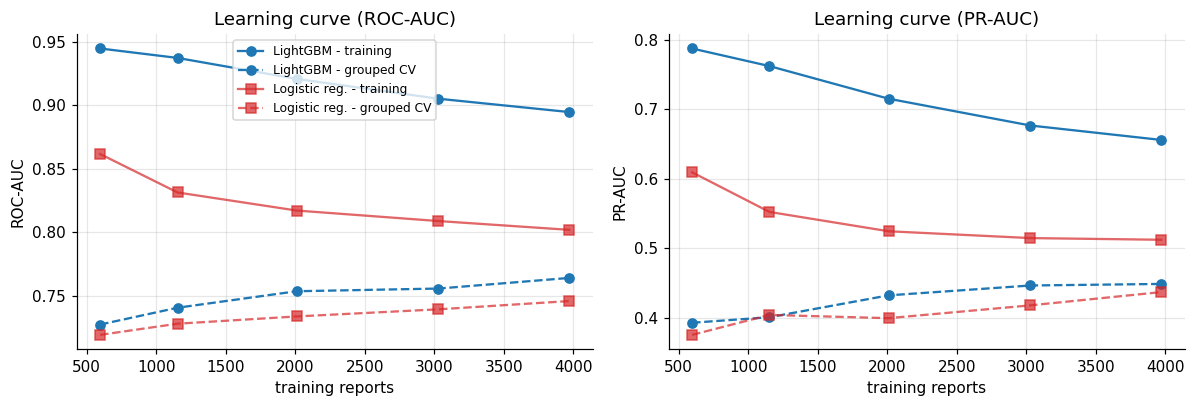

LightGBM                                                 Logistic regression                                                
         n_train_reports train ROC-AUC CV ROC-AUC train PR-AUC CV PR-AUC     n_train_reports train ROC-AUC CV ROC-AUC train PR-AUC CV PR-AUC
fraction                                                                                                                                    
0.15               595.9         0.945      0.727        0.787     0.393               595.9         0.862      0.719        0.610     0.376
0.30              1152.4         0.937      0.740        0.762     0.401              1152.4         0.831      0.728        0.553     0.405
0.50              2009.1         0.921      0.753        0.715     0.433              2009.1         0.817      0.734        0.525     0.400
0.75              3029.2         0.905      0.756        0.677     0.447              3029.2         0.809      0.739        0.515     0.418
1.00              3969.6         0.895      0.764        0.656     0.449              3969.6         0.802      0.746        0.513     0.437

In [9]:
def learning_curve(names, num, cat, fractions=(0.15, 0.3, 0.5, 0.75, 1.0), repeats=2):
    out = []
    for r in range(repeats):
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=r).split(num, y, groups):
            ug = np.array(sorted(set(groups[tr])))
            rng = np.random.default_rng(r)
            order = rng.permutation(ug)
            for f in fractions:
                keep = set(order[: max(20, int(f * len(ug)))])
                sub = tr[np.isin(groups[tr], list(keep))]
                p_tr, p_te = fit_predict(names, num, cat, sub, sub), fit_predict(names, num, cat, sub, te)
                out.append({"fraction": f, "n_train_reports": len(sub),
                            "train ROC-AUC": roc_auc_score(y[sub], p_tr), "CV ROC-AUC": roc_auc_score(y[te], p_te),
                            "train PR-AUC": average_precision_score(y[sub], p_tr),
                            "CV PR-AUC": average_precision_score(y[te], p_te)})
    return pd.DataFrame(out).groupby("fraction").mean()

lc = learning_curve(["LightGBM"], NUM2, CAT2)
lc_lr = learning_curve(["Logistic regression"], NUM2, CAT2)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, met in zip(ax, ["ROC-AUC", "PR-AUC"]):
    a.plot(lc["n_train_reports"], lc[f"train {met}"], "o-", c="#1f77b4", label="LightGBM - training")
    a.plot(lc["n_train_reports"], lc[f"CV {met}"], "o--", c="#1f77b4", label="LightGBM - grouped CV")
    a.plot(lc_lr["n_train_reports"], lc_lr[f"train {met}"], "s-", c="#d62728", alpha=.7, label="Logistic reg. - training")
    a.plot(lc_lr["n_train_reports"], lc_lr[f"CV {met}"], "s--", c="#d62728", alpha=.7, label="Logistic reg. - grouped CV")
    a.set_xlabel("training reports"); a.set_ylabel(met); a.set_title(f"Learning curve ({met})"); a.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
display(pd.concat({"LightGBM": lc, "Logistic regression": lc_lr}, axis=1).round(3))

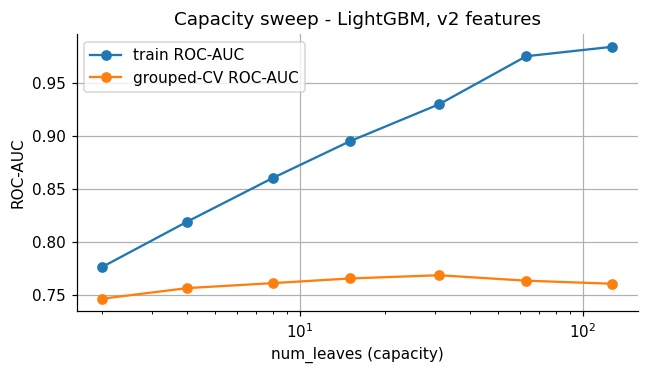

,train ROC-AUC,grouped-CV ROC-AUC,CV SD
num_leaves (capacity),,,
2,0.776,0.746,0.021
4,0.819,0.756,0.030
8,0.860,0.761,0.033
15,0.895,0.765,0.032
31,0.930,0.768,0.029
63,0.975,0.763,0.025
127,0.984,0.760,0.023


In [10]:
sweep = []
for leaves in [2, 4, 8, 15, 31, 63, 127]:
    MODELS["_sweep"] = (lambda L=leaves: LGBMClassifier(n_estimators=400, learning_rate=0.02, num_leaves=L,
                         min_child_samples=10 if L > 31 else 20, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.5, reg_lambda=1 if L > 31 else 5, verbose=-1, n_jobs=N_JOBS,
                         random_state=0), False)
    tr_s, cv_s = [], []
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(NUM2, y, groups):
        tr_s.append(roc_auc_score(y[tr], fit_predict(["_sweep"], NUM2, CAT2, tr, tr)))
        cv_s.append(roc_auc_score(y[te], fit_predict(["_sweep"], NUM2, CAT2, tr, te)))
    sweep.append({"num_leaves (capacity)": leaves, "train ROC-AUC": np.mean(tr_s), "grouped-CV ROC-AUC": np.mean(cv_s),
                  "CV SD": np.std(cv_s)})
del MODELS["_sweep"]
sweep = pd.DataFrame(sweep).set_index("num_leaves (capacity)")
ax = sweep[["train ROC-AUC", "grouped-CV ROC-AUC"]].plot(marker="o", figsize=(6, 3.5), logx=True, grid=True,
                                                          title="Capacity sweep - LightGBM, v2 features")
ax.set_ylabel("ROC-AUC"); plt.tight_layout(); plt.show()
display(sweep.round(3))

In [11]:
# Label-noise ceiling: reports with IDENTICAL inputs but different outcomes, and variants with discordant patients.
key_all = pd.util.hash_pandas_object(pd.concat([NUM2.round(6), CAT2], axis=1), index=False)
grp_in = pd.DataFrame({"k": key_all.values, "y": y}).groupby("k")["y"].agg(["size", "mean"])
conf = grp_in[(grp_in["size"] > 1) & (grp_in["mean"] > 0) & (grp_in["mean"] < 1)]
n_conf = int(conf["size"].sum())
unavoidable = int((conf["size"] * np.minimum(conf["mean"], 1 - conf["mean"])).sum())
var = pd.DataFrame({"g": groups, "y": y}).groupby("g")["y"].agg(["size", "mean"])
multi = var[var["size"] >= 2]
disc = multi[(multi["mean"] > 0) & (multi["mean"] < 1)]
print(f"Reports sharing an identical input vector with a report of the OPPOSITE outcome: {n_conf} "
      f"({n_conf / len(y):.1%}); at least {unavoidable} of them ({unavoidable / len(y):.1%}) must be misclassified by ANY model.")
print(f"Variants carried by 2+ labelled patients: {len(multi)}; with patients of both outcomes: {len(disc)} "
      f"({len(disc) / len(multi):.1%}), covering {int(disc['size'].sum())} reports.")

Reports sharing an identical input vector with a report of the OPPOSITE outcome: 609 (12.3%); at least 160 of them (3.2%) must be misclassified by ANY model.
Variants carried by 2+ labelled patients: 595; with patients of both outcomes: 135 (22.7%), covering 1400 reports.


**Answer to comment 3.** The measurements do not show classic high bias:

* **Training AUC is far above CV AUC** for the tree models (learning curve and capacity sweep) — that is a *variance* gap,
  not under-fitting. Only the deliberately simple logistic regression has train ≈ CV.
* **More capacity does not help.** From 8 to 127 leaves (16x the capacity) training AUC climbs from 0.86 to 0.98 while
  CV AUC stays between 0.760 and 0.768. Only the very simplest trees (2-4 leaves) score slightly lower in CV - that
  small piece is bias, and the 15-leaf setting used here is already past it. If bias were the main problem, larger
  models would keep scoring higher in CV.
* **More data helps only slowly.** The CV curve is still rising gently at the full training size: more labelled
  patients would help, a different algorithm would not.
* **Part of the error is irreducible with these inputs.** Patients with identical recorded inputs have opposite outcomes,
  and about a quarter of variants seen in several patients are discordant. Inhibitor development also depends on
  factors the dataset does not record — exposure days, product type, treatment intensity, HLA and family history
  (SIPPET, RODIN, CANAL). No model can recover information that is not in the data.

What the reviewer correctly observed is that **the overall performance is modest**. That is a property of the
information available (genotype + baseline severity/FVIII level), not of the learning algorithm; the improvements in
Section 6 therefore target better *features* and a *variance-reducing* ensemble rather than larger models.

## 6. Improvements and before/after results

| Change | Why |
|---|---|
| **26 new biology features (v2)**: null-variant flag, CpG transition signature, relative position, heavy/light chain, distance to the five immunodominant inhibitor epitopes and to functional sites, truncation fraction, NMD escape, Grantham and BLOSUM62 substitution scores, volume/polarity/aromatic change, severity ordinal, FVIII < 1 % flag, and literature-named interactions (null × severe; missense × C1/C2, × A2, × mild) | Encodes mechanisms reported in the literature (Gouw 2012 null-variant risk; Eckhardt 2013 missense hotspots) so the model needs fewer patients to learn them |
| **Four-model probability ensemble** (LightGBM + XGBoost + CatBoost + random forest) | Averages away part of the variance identified in Section 5 |
| **Threshold from inner CV** (max MCC), plus an accuracy-tuned threshold for reference | Removes the arbitrary 0.5 cut-off without touching the test fold |
| **Per-fold metrics, 5 × 5 repeated grouped CV** | Fixes the pooling artefact; gives honest uncertainty |

Explored but **not** adopted (no gain, kept out to stay simple): fold-safe "neighbourhood" target encodings (inhibitor rate
of training variants at nearby residues / same residue / same exon) gave ROC-AUC 0.763 vs 0.766 without them.

The cell below is the main experiment (≈20 min). The **v1 + CatBoost** row is the report's selected model on the report's
feature set, re-run under the same folds, so the comparison is like for like.

In [12]:
t = time.time()
runs = {}
runs["Majority class"] = evaluate(["Majority class"], NUM1, CAT1, label="Majority class (reference)")
runs["v1 CatBoost"] = evaluate(["CatBoost"], NUM1, CAT1, label="BEFORE: v1 features + CatBoost (report's model)")
runs["v2 LightGBM"] = evaluate(["LightGBM"], NUM2, CAT2, label="v2 features + LightGBM")
runs["v2 Ensemble"] = evaluate(ENSEMBLE, NUM2, CAT2, label="AFTER: v2 features + 4-model ensemble")
per_fold = pd.concat([r[0] for r in runs.values()], ignore_index=True)
print(f"done in {(time.time() - t) / 60:.1f} min")
headline = summarise(per_fold)
display(headline.T)

done in 16.5 min


model,Majority class (reference),BEFORE: v1 features + CatBoost (report's model),v2 features + LightGBM,AFTER: v2 features + 4-model ensemble
ROC-AUC,0.5 ± 0.0,0.76 ± 0.042,0.768 ± 0.045,0.768 ± 0.045
PR-AUC,0.168 ± 0.018,0.445 ± 0.057,0.455 ± 0.056,0.457 ± 0.057
MCC,0.0 ± 0.0,0.312 ± 0.065,0.332 ± 0.055,0.337 ± 0.059
Balanced accuracy,0.5 ± 0.0,0.663 ± 0.046,0.683 ± 0.042,0.687 ± 0.047
F1,0.0 ± 0.0,0.422 ± 0.067,0.448 ± 0.056,0.452 ± 0.063
Sensitivity,0.0 ± 0.0,0.484 ± 0.159,0.53 ± 0.131,0.538 ± 0.147
Specificity,1.0 ± 0.0,0.842 ± 0.094,0.837 ± 0.055,0.835 ± 0.061
Precision,0.0 ± 0.0,0.419 ± 0.096,0.404 ± 0.055,0.405 ± 0.042
Brier,0.14 ± 0.012,0.119 ± 0.01,0.117 ± 0.009,0.117 ± 0.009
Accuracy,0.832 ± 0.018,0.782 ± 0.058,0.786 ± 0.029,0.787 ± 0.031


,before (mean),after (mean),change,folds improved (of 25)
metric,,,,
ROC-AUC,0.760,0.768,0.009,21
PR-AUC,0.445,0.457,0.011,21
MCC,0.312,0.337,0.024,18
Balanced accuracy,0.663,0.687,0.024,21
F1,0.422,0.452,0.030,20
Sensitivity,0.484,0.538,0.055,13
Brier,0.119,0.117,-0.002,25
Accuracy,0.782,0.787,0.004,9


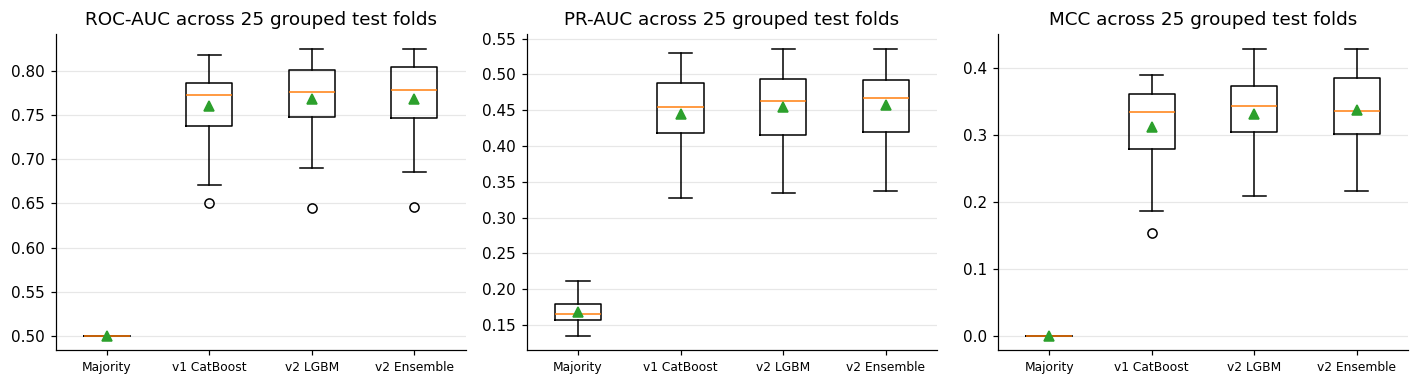

In [13]:
base = per_fold[per_fold["model"].str.startswith("BEFORE")].set_index(["repeat", "fold"])
aft = per_fold[per_fold["model"].str.startswith("AFTER")].set_index(["repeat", "fold"])
delta = []
for m in ["ROC-AUC", "PR-AUC", "MCC", "Balanced accuracy", "F1", "Sensitivity", "Brier", "Accuracy"]:
    d = aft[m] - base[m]
    better = (d < 0) if m == "Brier" else (d > 0)
    delta.append({"metric": m, "before (mean)": base[m].mean(), "after (mean)": aft[m].mean(),
                  "change": d.mean(), "folds improved (of 25)": int(better.sum())})
delta = pd.DataFrame(delta).set_index("metric")
display(delta.round(4))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, m in zip(ax, ["ROC-AUC", "PR-AUC", "MCC"]):
    data = [per_fold.loc[per_fold["model"] == k, m] for k in per_fold["model"].unique()]
    a.boxplot(data, labels=["Majority", "v1 CatBoost", "v2 LGBM", "v2 Ensemble"], showmeans=True)
    a.set_title(f"{m} across 25 grouped test folds"); a.grid(alpha=.3, axis="y"); a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

### 6.1 One held-out test split (for the confusion matrix and curves)

Repeated CV is the headline. For presentation, the same pipeline is also run once on a variant-grouped 80/20 split:
thresholds come from inner CV on the 80 %, the 20 % is scored once, and 95 % confidence intervals come from 1,000
bootstrap resamples **of variant groups**.

Held-out test: 979 reports, 157 with inhibitor, 505 unseen variants


,BEFORE: v1 + CatBoost,AFTER: v2 ensemble
ROC-AUC,0.778 [0.728-0.828],0.790 [0.739-0.835]
PR-AUC,0.471 [0.375-0.582],0.469 [0.369-0.581]
MCC,0.338 [0.242-0.439],0.335 [0.253-0.433]
Balanced accuracy,0.696 [0.647-0.743],0.705 [0.658-0.756]
F1,0.456 [0.371-0.543],0.455 [0.379-0.539]
Sensitivity,0.567 [0.467-0.656],0.624 [0.527-0.719]
Specificity,0.825 [0.754-0.885],0.786 [0.710-0.855]
Precision,0.382 [0.289-0.493],0.358 [0.281-0.453]
Accuracy,0.783 [0.727-0.836],0.760 [0.700-0.818]
Majority-class accuracy,0.840,0.840


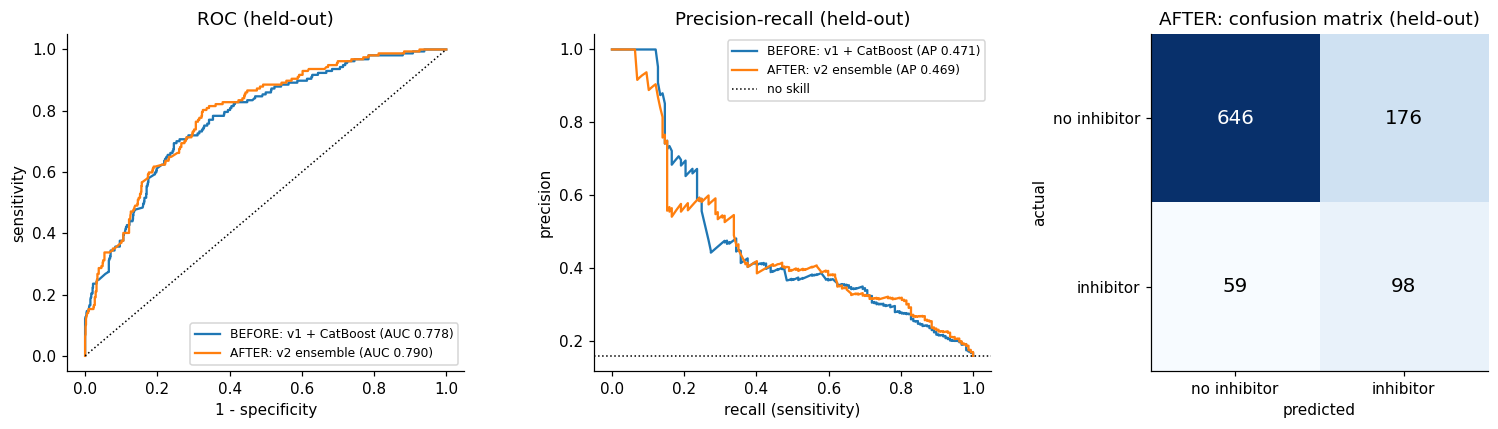

In [14]:
tr, te = next(StratifiedGroupKFold(5, shuffle=True, random_state=2026).split(NUM2, y, groups))
def holdout(names, num, cat):
    inner_p = np.full(len(tr), np.nan)
    for itr, ite in StratifiedGroupKFold(3, shuffle=True, random_state=7).split(tr, y[tr], groups[tr]):
        inner_p[ite] = fit_predict(names, num, cat, tr[itr], tr[ite])
    thr = best_threshold(y[tr], inner_p, "mcc")
    return fit_predict(names, num, cat, tr, te), thr

def group_bootstrap(p, thr, n=1000, seed=0):
    rng, g_te = np.random.default_rng(seed), groups[te]
    ug = np.unique(g_te); pos = {g: np.where(g_te == g)[0] for g in ug}
    stats = []
    for _ in range(n):
        idx = np.concatenate([pos[g] for g in rng.choice(ug, len(ug))])
        if y[te][idx].min() == y[te][idx].max():
            continue
        stats.append(metric_panel(y[te][idx], p[idx], thr))
    return pd.DataFrame(stats).quantile([0.025, 0.975])

HO = {"BEFORE: v1 + CatBoost": holdout(["CatBoost"], NUM1, CAT1), "AFTER: v2 ensemble": holdout(ENSEMBLE, NUM2, CAT2)}
rows = {}
for k, (p, thr) in HO.items():
    m, ci = metric_panel(y[te], p, thr), group_bootstrap(p, thr)
    rows[k] = {c: f"{m[c]:.3f} [{ci.loc[0.025, c]:.3f}-{ci.loc[0.975, c]:.3f}]" for c in
               ["ROC-AUC", "PR-AUC", "MCC", "Balanced accuracy", "F1", "Sensitivity", "Specificity", "Precision",
                "Accuracy"]}
    rows[k]["Majority-class accuracy"] = f"{m['Majority-class accuracy']:.3f}"
print(f"Held-out test: {len(te)} reports, {y[te].sum()} with inhibitor, {len(set(groups[te]))} unseen variants")
display(pd.DataFrame(rows))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for k, (p, thr) in HO.items():
    fpr, tpr, _ = roc_curve(y[te], p); pr, rc, _ = precision_recall_curve(y[te], p)
    ax[0].plot(fpr, tpr, label=f"{k} (AUC {roc_auc_score(y[te], p):.3f})")
    ax[1].plot(rc, pr, label=f"{k} (AP {average_precision_score(y[te], p):.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[1].axhline(y[te].mean(), c="k", ls=":", lw=1, label="no skill")
ax[0].set(xlabel="1 - specificity", ylabel="sensitivity", title="ROC (held-out)"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="recall (sensitivity)", ylabel="precision", title="Precision-recall (held-out)"); ax[1].legend(fontsize=8)
p, thr = HO["AFTER: v2 ensemble"]
cm = confusion_matrix(y[te], p >= thr)
ax[2].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[2].text(j, i, v, ha="center", va="center", fontsize=13, color="white" if v > cm.max() / 2 else "black")
ax[2].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["no inhibitor", "inhibitor"], yticklabels=["no inhibitor", "inhibitor"],
          xlabel="predicted", ylabel="actual", title="AFTER: confusion matrix (held-out)")
plt.tight_layout(); plt.show()

A single 20 % test split holds only ~160 inhibitor cases, so its 95 % intervals are wide and overlap between the two
models: one split cannot rank them. This is why the 25-fold repeated CV above is the headline result and the held-out
split is only an illustration.

## 7. The "known-variant" use case

Sections 3–6 test the hardest, cleanest case: a patient whose variant has **never been reported** before. Clinically,
many new patients carry a variant that *has* been reported in other patients. Here the split groups by
**variant × publication**: a test patient's variant may appear in training, but only through *other* publications, so
duplicate reports from one paper can never sit on both sides (the leak that the report's "split by report" row had).

In [15]:
grp_vp = (df["variant_key"].astype(str) + "|" + df["ref_id"].astype(str)).to_numpy(dtype=object)
seen = np.mean([np.isin(groups[te_], groups[tr_]).mean()
                for tr_, te_ in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(NUM2, y, grp_vp)])
kv, _ = evaluate(ENSEMBLE, NUM2, CAT2, grp=grp_vp, repeats=3, label="Known-variant setting: v2 ensemble")
print(f"Share of test reports whose variant was reported (by another publication) in training: {seen:.1%}")
display(summarise(kv).T)

Share of test reports whose variant was reported (by another publication) in training: 55.8%


model,Known-variant setting: v2 ensemble
ROC-AUC,0.797 ± 0.017
PR-AUC,0.493 ± 0.044
MCC,0.366 ± 0.033
Balanced accuracy,0.703 ± 0.027
F1,0.479 ± 0.031
Sensitivity,0.569 ± 0.102
Specificity,0.837 ± 0.058
Precision,0.425 ± 0.045
Brier,0.113 ± 0.008
Accuracy,0.793 ± 0.035


## 8. Comparison with the literature — why papers report > 90 %

The reviewer notes that the surveyed papers report accuracy above 90 %. To compare like with like, the **base paper's
protocol (Singh & Singh 2025, 97.37 % accuracy on CDC CHAMP) is re-run on our own data**, and its ingredients are
removed one at a time:

* **A** – their protocol: "Not reported"/blank outcomes counted as **no inhibitor**; the HGVS cDNA name label-encoded as a
  feature; random over-sampling (ROS) to 50/50 **before** the train/test split; random (not grouped) 5-fold CV; random forest.
* **B** – ROS moved inside the training folds only.
* **C** – HGVS identifier removed.
* **D** – unknown outcomes removed instead of being called negative.
* **E** – variant-grouped split (this project's protocol).

`test rows copied in train` is the share of test rows whose entire feature vector also occurs in the training fold.

In [16]:
dfa, _ = load_reports(keep_unknown=True)
ba = base_columns(dfa); n_a, c_a = features_v1(ba)
Xa = pd.concat([n_a.fillna(-999), c_a.apply(lambda s: s.astype("category").cat.codes)], axis=1).reset_index(drop=True)
Xa_id = Xa.assign(hgvs_cdna_code=dfa["mut_syn"].astype("category").cat.codes.values)
ya_lab = dfa["y"]; known = ya_lab.notna().to_numpy(); ga = dfa["variant_key"].to_numpy(dtype=object)

def lit_protocol(X, yv, grp=None, ros_before=False, ros_inside=False, seed=0):
    X, yv, rng = X.reset_index(drop=True), np.asarray(yv).astype(int), np.random.default_rng(seed)
    if ros_before:
        pos, neg = np.where(yv == 1)[0], np.where(yv == 0)[0]
        idx = np.concatenate([neg, pos, rng.choice(pos, len(neg) - len(pos))])
        X, yv = X.iloc[idx].reset_index(drop=True), yv[idx]
        grp = grp[idx] if grp is not None else None
    cv = StratifiedGroupKFold(5, shuffle=True, random_state=seed) if grp is not None else StratifiedKFold(5, shuffle=True, random_state=seed)
    res = []
    for tr_, te_ in cv.split(X, yv, grp):
        Xtr, ytr = X.iloc[tr_], yv[tr_]
        if ros_inside:
            pos, neg = np.where(ytr == 1)[0], np.where(ytr == 0)[0]
            ii = np.concatenate([neg, pos, rng.choice(pos, len(neg) - len(pos))]); Xtr, ytr = Xtr.iloc[ii], ytr[ii]
        m = RandomForestClassifier(300, n_jobs=N_JOBS, random_state=seed).fit(Xtr, ytr)
        p = m.predict_proba(X.iloc[te_])[:, 1]; pred = (p >= 0.5).astype(int)
        trset = set(map(tuple, X.iloc[tr_].to_numpy()))
        res.append({"Accuracy": accuracy_score(yv[te_], pred), "ROC-AUC": roc_auc_score(yv[te_], p),
                    "F1": f1_score(yv[te_], pred), "MCC": matthews_corrcoef(yv[te_], pred),
                    "Majority-class accuracy": max(yv[te_].mean(), 1 - yv[te_].mean()),
                    "test rows copied in train": np.mean([tuple(r) in trset for r in X.iloc[te_].to_numpy()])})
    out = pd.DataFrame(res).mean(); out["rows"] = len(yv); out["prevalence"] = yv.mean()
    return out

y_unk0 = ya_lab.fillna(0).to_numpy()
lit = pd.DataFrame({
    "A. Literature protocol (unknown=0, HGVS id, ROS before split, random split)": lit_protocol(Xa_id, y_unk0, ros_before=True),
    "B. = A, but ROS inside training folds only": lit_protocol(Xa_id, y_unk0, ros_inside=True),
    "C. = B, without the HGVS identifier": lit_protocol(Xa, y_unk0, ros_inside=True),
    "D. = C, unknown outcomes removed (not set to 0)": lit_protocol(Xa[known], ya_lab[known].to_numpy(), ros_inside=True),
    "E. = D, variant-grouped split (this project)": lit_protocol(Xa[known], ya_lab[known].to_numpy(), grp=ga[known], ros_inside=True),
}).T
display(lit.round(3))

,Accuracy,ROC-AUC,F1,MCC,Majority-class accuracy,test rows copied in train,rows,prevalence
"A. Literature protocol (unknown=0, HGVS id, ROS before split, random split)",0.940,0.985,0.942,0.883,0.500,0.650,15860.0,0.500
"B. = A, but ROS inside training folds only",0.859,0.742,0.313,0.236,0.905,0.301,8766.0,0.095
"C. = B, without the HGVS identifier",0.860,0.742,0.325,0.249,0.905,0.314,8766.0,0.095
"D. = C, unknown outcomes removed (not set to 0)",0.805,0.761,0.439,0.321,0.832,0.297,4962.0,0.168
"E. = D, variant-grouped split (this project)",0.798,0.727,0.383,0.265,0.831,0.015,4962.0,0.168


**Reading the table.**

* Row **A** reproduces the literature-level result on our data: accuracy and F1 in the 90s and ROC-AUC ≈ 0.98. But about
  two-thirds of the test rows are exact copies of training rows, because over-sampling duplicated positive patients
  *before* splitting. The model is recognising copies, not predicting new patients.
* Moving the over-sampling inside the training folds (**B**) collapses accuracy to *below* the majority-class accuracy
  of that setting and ROC-AUC to ≈0.74 — row A's score came from the duplication.
* Setting unknown outcomes to "no inhibitor" (A–C) adds 3,804 invented negatives and pushes the majority baseline
  to ≈90 %, which makes any accuracy look high.
* With honest labels and a split by variant (**E**) a plain random forest sits where our models sit (Section 6).

The over-sampling leak alone accounts for most of the gap between the literature's > 90 % and our ≈80 %.

In [17]:
# Rawal et al. 2024 report F1 0.88-0.99 - but for predicting SEVERITY, not inhibitors. Same task on our data:
dfs, _ = load_reports(keep_unknown=True)
bs = base_columns(dfs); ns, cs = features_v2(bs)
clin = ["log_fviii_activity", "log_fviii_antigen", "severity_ordinal", "fviii_below_1", "fviii_measured", "null_x_severe",
        "missense_x_mild"]
ns = ns.drop(columns=clin); cs = cs.drop(columns=["severity", "crm_type", "fviii_activity_kind", "fviii_antigen_kind",
                                                 "effect_x_severity"])
mask = bs["severity"].isin(["mild", "moderate", "severe"]).to_numpy()
ys = (bs["severity"] == "severe").astype(int).to_numpy()[mask]; gs = dfs["variant_key"].to_numpy(dtype=object)[mask]
ns, cs = ns[mask].reset_index(drop=True), cs[mask].reset_index(drop=True)
Xs = pd.concat([ns, cs], axis=1); sev = []
for tr_, te_ in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(Xs, ys, gs):
    pipe = make_pipeline(encoder(ns, cs, False), MODELS["LightGBM"][0]()).fit(Xs.iloc[tr_], ys[tr_])
    p = pipe.predict_proba(Xs.iloc[te_])[:, 1]
    sev.append({"ROC-AUC": roc_auc_score(ys[te_], p), "F1 (weighted)": f1_score(ys[te_], p >= .5, average="weighted"),
                "Accuracy": accuracy_score(ys[te_], p >= .5)})
sev = pd.DataFrame(sev).agg(["mean", "std"]).round(3)
print(f"Severity task (severe vs non-severe) from GENOTYPE ONLY, variant-grouped, {mask.sum():,} reports:")
display(sev)

Severity task (severe vs non-severe) from GENOTYPE ONLY, variant-grouped, 7,844 reports:


,ROC-AUC,F1 (weighted),Accuracy
mean,0.855,0.796,0.795
std,0.011,0.017,0.017


Predicting **severity** from the genotype is a much easier task than predicting **inhibitors**: on the same data, the
same strict variant-grouped split and the same model, severity reaches a clearly higher ROC-AUC (≈0.85) than inhibitor
status (≈0.76). Rawal et al.'s F1 of 0.88–0.99 is higher still because they work at variant level with sequence
descriptors and without our grouping by variant. Either way, their numbers answer a different question; in our model
severity is an *input*, not the outcome.

In [18]:
ens = per_fold[per_fold["model"].str.startswith("AFTER")]
kvm = kv
f = lambda d, c: f"{d[c].mean():.3f}"
comparison = pd.DataFrame([
    ["Singh & Singh 2025 (base paper 1)", "CDC CHAMP, ~4,000 variant rows", "Inhibitor (yes/no)",
     "ROS before split; 'Not reported' = no; HGVS id as feature; random split", "Accuracy 97.37 % (RF)",
     f"Same protocol on our data: accuracy {lit.iloc[0]['Accuracy']:.1%}, AUC {lit.iloc[0]['ROC-AUC']:.3f}; "
     f"leak removed: accuracy {lit.iloc[4]['Accuracy']:.1%}, AUC {lit.iloc[4]['ROC-AUC']:.3f}",
     "Score comes from duplicated test rows and invented negatives (Section 8, rows A-E)"],
    ["Jardim et al. 2024, HemfilNET (base paper 2)", "95 previously untreated children, Brazil", "Inhibitor by 75 exposure days",
     "37 prospective pre-treatment clinical + biological variables; leave-one-out CV", "Accuracy 90.5 %",
     "Not reproducible - variables not in any public registry",
     "Prospective cohort with exposure & biomarker data; 33 % prevalence; LOOCV on n=95 is high-variance"],
    ["Rawal et al. 2024 (base paper 3)", "Several F8 repositories", "Severity (not inhibitor)",
     "Sequence-derived features", "F1 0.88-0.99",
     f"Severity from genotype on our data: F1 {sev.loc['mean', 'F1 (weighted)']:.3f}, AUC {sev.loc['mean', 'ROC-AUC']:.3f}",
     "Different, easier task; severity is an input in our model"],
    ["Fan et al. 2025 (base paper 4)", "60 patients + 23 controls", "Association with inhibitor presence",
     "Cytokine / N-glycan regression", "Associations (no accuracy)", "-", "Cross-sectional biomarker study, not a predictor"],
    ["Hashemi et al. 2015", "825 previously untreated patients", "Inhibitor", "Clinical risk score (logistic)", "AUC ≈ 0.69",
     f"Our AUC {f(ens, 'ROC-AUC')} (novel variants)", "Uses family history & treatment intensity; external validation lower"],
    ["Hassan et al. 2021 (SIPPET validation)", "251 patients", "Inhibitor", "External validation of risk scores",
     "C-statistic 0.53; new model 0.66", f"Our AUC {f(ens, 'ROC-AUC')}", "Shows the realistic ceiling of clinical scores"],
    ["This project - BEFORE (report)", "EAHAD, 4,962 patient reports", "Inhibitor", "Variant-grouped CV",
     "-", f"AUC {f(base, 'ROC-AUC')}, PR-AUC {f(base, 'PR-AUC')}, MCC {f(base, 'MCC')}, acc {f(base, 'Accuracy (accuracy-tuned threshold)')}", "Report's selected model, re-run"],
    ["This project - AFTER (novel variant)", "EAHAD, 4,962 patient reports", "Inhibitor", "Variant-grouped 5x5 CV, inner-CV thresholds",
     "-", f"AUC {f(ens, 'ROC-AUC')}, PR-AUC {f(ens, 'PR-AUC')}, MCC {f(ens, 'MCC')}, acc {f(ens, 'Accuracy (accuracy-tuned threshold)')}", "Strict, leakage-free estimate"],
    ["This project - AFTER (known variant)", "EAHAD, 4,962 patient reports", "Inhibitor", "Grouped by variant x publication",
     "-", f"AUC {f(kvm, 'ROC-AUC')}, PR-AUC {f(kvm, 'PR-AUC')}, MCC {f(kvm, 'MCC')}, acc {f(kvm, 'Accuracy (accuracy-tuned threshold)')}", "Patient's variant already reported elsewhere"],
], columns=["Study", "Data", "Task", "Protocol", "Reported result", "Result in our experiments", "Why the numbers differ"])
with pd.option_context("display.max_colwidth", 120):
    display(comparison.set_index("Study"))
Path("results_02").mkdir(exist_ok=True)
comparison.to_csv("results_02/literature_comparison.csv", index=False)
per_fold.to_csv("results_02/per_fold_metrics.csv", index=False)
lit.to_csv("results_02/literature_protocol_replication.csv")

,Data,Task,Protocol,Reported result,Result in our experiments,Why the numbers differ
Study,,,,,,
Singh & Singh 2025 (base paper 1),"CDC CHAMP, ~4,000 variant rows",Inhibitor (yes/no),ROS before split; 'Not reported' = no; HGVS id as feature; random split,Accuracy 97.37 % (RF),"Same protocol on our data: accuracy 94.0%, AUC 0.985; leak removed: accuracy 79.8%, AUC 0.727","Score comes from duplicated test rows and invented negatives (Section 8, rows A-E)"
"Jardim et al. 2024, HemfilNET (base paper 2)","95 previously untreated children, Brazil",Inhibitor by 75 exposure days,37 prospective pre-treatment clinical + biological variables; leave-one-out CV,Accuracy 90.5 %,Not reproducible - variables not in any public registry,Prospective cohort with exposure & biomarker data; 33 % prevalence; LOOCV on n=95 is high-variance
Rawal et al. 2024 (base paper 3),Several F8 repositories,Severity (not inhibitor),Sequence-derived features,F1 0.88-0.99,"Severity from genotype on our data: F1 0.796, AUC 0.855","Different, easier task; severity is an input in our model"
Fan et al. 2025 (base paper 4),60 patients + 23 controls,Association with inhibitor presence,Cytokine / N-glycan regression,Associations (no accuracy),-,"Cross-sectional biomarker study, not a predictor"
Hashemi et al. 2015,825 previously untreated patients,Inhibitor,Clinical risk score (logistic),AUC ≈ 0.69,Our AUC 0.768 (novel variants),Uses family history & treatment intensity; external validation lower
Hassan et al. 2021 (SIPPET validation),251 patients,Inhibitor,External validation of risk scores,C-statistic 0.53; new model 0.66,Our AUC 0.768,Shows the realistic ceiling of clinical scores
This project - BEFORE (report),"EAHAD, 4,962 patient reports",Inhibitor,Variant-grouped CV,-,"AUC 0.760, PR-AUC 0.445, MCC 0.312, acc 0.843","Report's selected model, re-run"
This project - AFTER (novel variant),"EAHAD, 4,962 patient reports",Inhibitor,"Variant-grouped 5x5 CV, inner-CV thresholds",-,"AUC 0.768, PR-AUC 0.457, MCC 0.337, acc 0.842","Strict, leakage-free estimate"
This project - AFTER (known variant),"EAHAD, 4,962 patient reports",Inhibitor,Grouped by variant x publication,-,"AUC 0.797, PR-AUC 0.493, MCC 0.366, acc 0.846",Patient's variant already reported elsewhere


## 9. What the improved model relies on (SHAP)

SHAP values for the v2 LightGBM fitted on all reports. One-hot columns are summed back to their source feature.

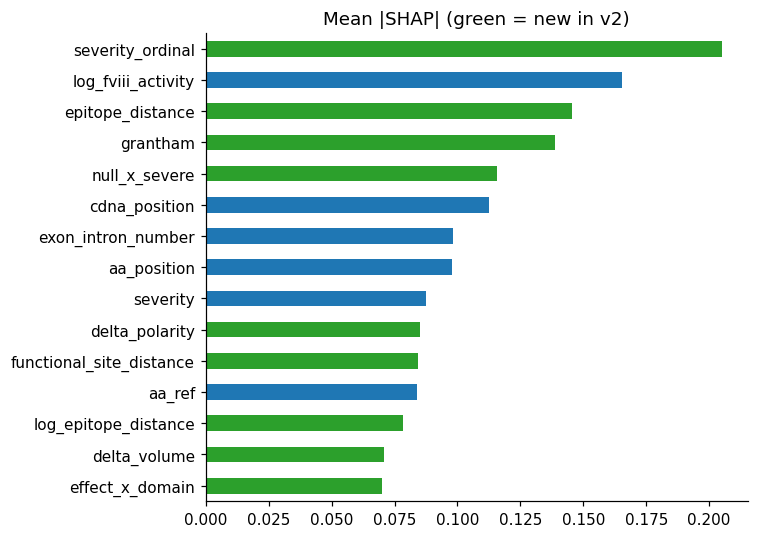

Share of attribution carried by the new v2 features: 55.3%


In [19]:
import shap
X2 = pd.concat([NUM2, CAT2], axis=1)
pipe = make_pipeline(encoder(NUM2, CAT2, False), MODELS["LightGBM"][0]()).fit(X2, y)
Z = pipe[:-1].transform(X2); names = pipe[:-1].get_feature_names_out()
sv = shap.TreeExplainer(pipe[-1]).shap_values(Z)
sv = sv[1] if isinstance(sv, list) else sv
cats = sorted(CAT2.columns, key=len, reverse=True)
def source(n):
    kind, rest = n.split("__", 1)
    return rest if kind == "num" else next(c for c in cats if rest.startswith(c + "_"))
imp = pd.Series(np.abs(sv).mean(0), index=[source(n) for n in names]).groupby(level=0).sum().sort_values()
new = set(NUM2.columns) - set(NUM1.columns) | {"effect_x_severity", "effect_x_domain"}
top = imp.tail(15)
top.plot.barh(figsize=(7, 5), color=["#2ca02c" if i in new else "#1f77b4" for i in top.index])
plt.title("Mean |SHAP| (green = new in v2)"); plt.tight_layout(); plt.show()
print(f"Share of attribution carried by the new v2 features: {imp[imp.index.isin(new)].sum() / imp.sum():.1%}")

## 10. Summary for the reviewer

In [20]:
B, A = base, ens
s = lambda d, c: f"{d[c].mean():.3f} ± {d[c].std():.3f}"
display(Markdown(f"""
**1. "Train CV ROC-AUC < 50 %."** The 0.453 in the report is the *majority-class baseline*, lowered below 0.5 by pooling
out-of-fold predictions. Per fold it is exactly 0.5. Every trained model scored 0.73-0.76 in CV, consistent with test.
All metrics are now computed per fold.

**2. "ROC-AUC is not a good metric."** The headline is now PR-AUC, MCC, balanced accuracy, F1, sensitivity,
specificity, precision and Brier score, each next to its no-skill value.

**3. "High bias, low variance."** Training AUC is well above CV AUC, and beyond 8 leaves CV AUC stays at 0.76-0.77 while
training AUC climbs to 0.98: the limit is the information in the inputs (identical inputs with opposite outcomes; ~{len(disc) / len(multi):.0%}
of multi-patient variants discordant; no exposure, product or HLA data), not under-fitting.

**4. Improvement (5×5 variant-grouped CV, same folds, thresholds from inner CV):**

| Metric | Before (report's CatBoost, v1) | After (v2 features + ensemble) | Folds improved |
|---|---|---|---|
| PR-AUC (no-skill {A['PR-AUC baseline (prevalence)'].mean():.3f}) | {s(B, 'PR-AUC')} | {s(A, 'PR-AUC')} | {delta.loc['PR-AUC', 'folds improved (of 25)']}/25 |
| ROC-AUC | {s(B, 'ROC-AUC')} | {s(A, 'ROC-AUC')} | {delta.loc['ROC-AUC', 'folds improved (of 25)']}/25 |
| MCC | {s(B, 'MCC')} | {s(A, 'MCC')} | {delta.loc['MCC', 'folds improved (of 25)']}/25 |
| Balanced accuracy | {s(B, 'Balanced accuracy')} | {s(A, 'Balanced accuracy')} | {delta.loc['Balanced accuracy', 'folds improved (of 25)']}/25 |
| F1 | {s(B, 'F1')} | {s(A, 'F1')} | {delta.loc['F1', 'folds improved (of 25)']}/25 |
| Brier (lower is better) | {s(B, 'Brier')} | {s(A, 'Brier')} | {delta.loc['Brier', 'folds improved (of 25)']}/25 |
| Accuracy, accuracy-tuned threshold (majority {A['Majority-class accuracy'].mean():.3f}) | {s(B, 'Accuracy (accuracy-tuned threshold)')} | {s(A, 'Accuracy (accuracy-tuned threshold)')} | |

In the **known-variant** setting (variant already reported by another publication) the ensemble reaches ROC-AUC
{s(kv, 'ROC-AUC')}, PR-AUC {s(kv, 'PR-AUC')}, MCC {s(kv, 'MCC')}.

**5. Literature comparison.** Re-running the base paper's protocol on our data gives accuracy
{lit.iloc[0]['Accuracy']:.1%} and ROC-AUC {lit.iloc[0]['ROC-AUC']:.3f}, with {lit.iloc[0]['test rows copied in train']:.0%} of
test rows duplicated from training. Removing over-sampling-before-split, the identifier feature and the "unknown = no"
relabelling brings the same random forest to accuracy {lit.iloc[4]['Accuracy']:.1%} / ROC-AUC {lit.iloc[4]['ROC-AUC']:.3f}.
The > 90 % figures are therefore a property of the evaluation protocol, not a level of prediction that genotype +
baseline clinical data can reach. Clinically validated risk scores built *with* treatment data reach 0.53-0.69 on
external cohorts; our {A['ROC-AUC'].mean():.3f} without treatment data is competitive with them.

Total run time: {(time.time() - T0) / 60:.1f} min.
"""))


**1. "Train CV ROC-AUC < 50 %."** The 0.453 in the report is the *majority-class baseline*, lowered below 0.5 by pooling
out-of-fold predictions. Per fold it is exactly 0.5. Every trained model scored 0.73-0.76 in CV, consistent with test.
All metrics are now computed per fold.

**2. "ROC-AUC is not a good metric."** The headline is now PR-AUC, MCC, balanced accuracy, F1, sensitivity,
specificity, precision and Brier score, each next to its no-skill value.

**3. "High bias, low variance."** Training AUC is well above CV AUC, and beyond 8 leaves CV AUC stays at 0.76-0.77 while
training AUC climbs to 0.98: the limit is the information in the inputs (identical inputs with opposite outcomes; ~23%
of multi-patient variants discordant; no exposure, product or HLA data), not under-fitting.

**4. Improvement (5×5 variant-grouped CV, same folds, thresholds from inner CV):**

| Metric | Before (report's CatBoost, v1) | After (v2 features + ensemble) | Folds improved |
|---|---|---|---|
| PR-AUC (no-skill 0.168) | 0.445 ± 0.057 | 0.457 ± 0.057 | 21/25 |
| ROC-AUC | 0.760 ± 0.042 | 0.768 ± 0.045 | 21/25 |
| MCC | 0.312 ± 0.065 | 0.337 ± 0.059 | 18/25 |
| Balanced accuracy | 0.663 ± 0.046 | 0.687 ± 0.047 | 21/25 |
| F1 | 0.422 ± 0.067 | 0.452 ± 0.063 | 20/25 |
| Brier (lower is better) | 0.119 ± 0.010 | 0.117 ± 0.009 | 25/25 |
| Accuracy, accuracy-tuned threshold (majority 0.832) | 0.843 ± 0.014 | 0.842 ± 0.015 | |

In the **known-variant** setting (variant already reported by another publication) the ensemble reaches ROC-AUC
0.797 ± 0.017, PR-AUC 0.493 ± 0.044, MCC 0.366 ± 0.033.

**5. Literature comparison.** Re-running the base paper's protocol on our data gives accuracy
94.0% and ROC-AUC 0.985, with 65% of
test rows duplicated from training. Removing over-sampling-before-split, the identifier feature and the "unknown = no"
relabelling brings the same random forest to accuracy 79.8% / ROC-AUC 0.727.
The > 90 % figures are therefore a property of the evaluation protocol, not a level of prediction that genotype +
baseline clinical data can reach. Clinically validated risk scores built *with* treatment data reach 0.53-0.69 on
external cohorts; our 0.768 without treatment data is competitive with them.

Total run time: 27.3 min.
